<a href="https://colab.research.google.com/github/ethereal-arko/Email_Spam_Classifier/blob/main/Email_Spam_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Email Spam Classifier

### Machine Learning-Based Spam Detection Using Natural Language Processing

## 1. Project Overview

Email spam is a common problem in digital communication. Spam messages may contain unwanted advertisements, misleading information, or potentially harmful links.

This project develops a machine learning model that classifies email messages into two categories:

- **Spam:** Unwanted or unsolicited messages.
- **Ham:** Legitimate, non-spam messages.

The model uses TF-IDF (Term Frequency-Inverse Document Frequency) to convert text messages into numerical features and Logistic Regression to perform classification.

## 2. Project Objectives

- Explore and understand the email dataset.
- Perform data quality checks and preprocessing.
- Convert text messages into numerical features using TF-IDF.
- Train a Logistic Regression classification model.
- Evaluate performance using appropriate classification metrics.
- Analyze incorrect predictions and investigate possible improvements.
- Develop a reusable prediction function for new messages.

## 3. Technologies Used

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Google Colab

## 4. Project Workflow

Dataset Collection → Data Inspection → Preprocessing → Exploratory Data Analysis → Feature Extraction → Model Training → Evaluation → Error Analysis → Prediction

## 5. Evaluation Strategy

Model performance will be evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.

The final evaluation will focus on the model's ability to identify spam messages while limiting false alarms on legitimate messages.


In [2]:

# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

# Set visualization style
sns.set_theme(style="whitegrid")

print("All required libraries imported successfully.")


All required libraries imported successfully.



## 6. Dataset Loading and Initial Inspection

In this section, the dataset is loaded into a Pandas DataFrame and examined to understand its structure, size, columns, and data types.

Initial inspection helps identify potential data quality issues before preprocessing and model training.


In [3]:

# Load the dataset

DATA_PATH = "/content/mail_data.csv"

raw_mail_data = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print(f"Number of rows: {raw_mail_data.shape[0]}")
print(f"Number of columns: {raw_mail_data.shape[1]}")

display(raw_mail_data.head())


Dataset loaded successfully.
Number of rows: 5572
Number of columns: 2


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"



### 6.1 Dataset Structure

The dataset structure is examined to identify the available columns, data types, and non-null values.

This step helps verify whether the dataset contains the expected message text and classification labels.


In [4]:

# Inspect column names and data types

print("Column names:")
print(raw_mail_data.columns.tolist())

print("\nDataset information:")
raw_mail_data.info()

print("\nStatistical summary of available columns:")
display(raw_mail_data.describe(include="all"))


Column names:
['Category', 'Message']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5572 non-null   object
 1   Message   5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Statistical summary of available columns:


,Category,Message
count,5572,5572
unique,2,5157
top,ham,"Sorry, I'll call later"
freq,4825,30



### 6.2 Data Quality Checks

Before preprocessing, the dataset is checked for missing values, duplicate rows, and repeated messages.

Repeated messages are not automatically removed because duplicates may represent legitimate repeated observations. Their presence will be considered during data cleaning and evaluation planning.


In [5]:

# Check missing values

print("Missing values in each column:")
display(raw_mail_data.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:")
print(raw_mail_data.duplicated().sum())

# Check duplicate message texts
print("\nNumber of duplicate messages:")
print(raw_mail_data["Message"].duplicated().sum())

# Check messages associated with conflicting labels
message_label_counts = (
    raw_mail_data.groupby("Message")["Category"].nunique()
)

print("\nMessages associated with multiple labels:")
print((message_label_counts > 1).sum())


Missing values in each column:


,0
Category,0
Message,0



Number of duplicate rows:
415

Number of duplicate messages:
415

Messages associated with multiple labels:
0



## 7. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution and characteristics of the messages before building the classification model.

### 7.1 Class Distribution

The dataset contains two target classes: `ham` and `spam`.

Analyzing the number and proportion of messages in each class helps determine whether the dataset is balanced or imbalanced. This is important when selecting evaluation metrics and interpreting model performance.


,Message Count,Percentage (%)
Category,,
ham,4825,86.59
spam,747,13.41


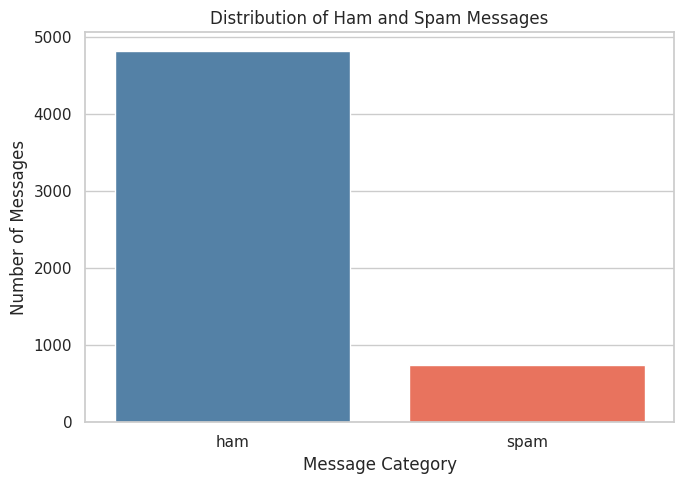

In [6]:

# Analyze class distribution

category_counts = raw_mail_data["Category"].value_counts()

category_percentages = (
    raw_mail_data["Category"].value_counts(normalize=True) * 100
)

class_summary = pd.DataFrame({
    "Message Count": category_counts,
    "Percentage (%)": category_percentages.round(2)
})

display(class_summary)

# Visualize class distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=raw_mail_data,
    x="Category",
    hue="Category",
    order=["ham", "spam"],
    palette={"ham": "steelblue", "spam": "tomato"},
    legend=False
)

plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()



### 7.2 Message Length Analysis

Message length is examined to understand whether ham and spam messages differ in their text length distributions.

A new analysis column is created without modifying the original dataset. Message length is measured as the number of characters in each message.

This analysis is exploratory and does not assume that message length alone can reliably identify spam.


,count,mean,median,min,max
Category,,,,,
ham,4825,71.45,52.0,2,910
spam,747,137.99,149.0,7,223


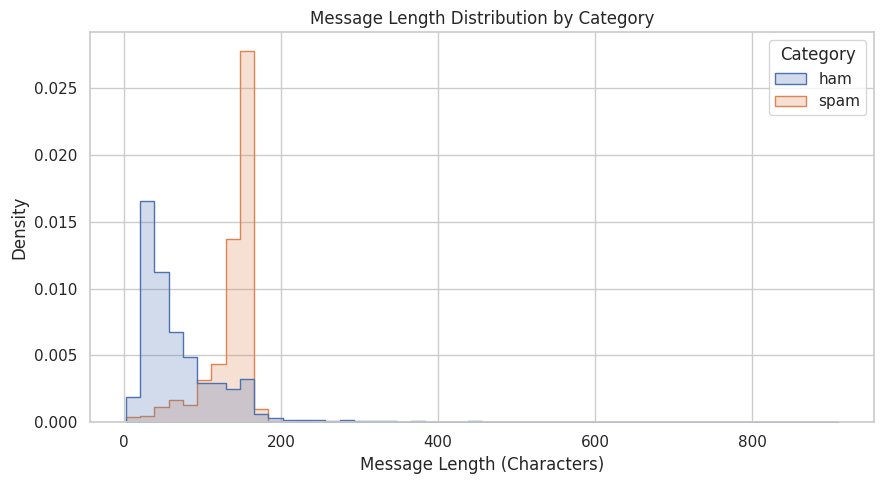

In [7]:

# Create a separate DataFrame for EDA
eda_data = raw_mail_data.copy()

# Calculate message length in characters
eda_data["Message_Length"] = (
    eda_data["Message"].str.len()
)

# Summary statistics by category
length_summary = (
    eda_data.groupby("Category")["Message_Length"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(length_summary)

# Visualize message length distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=eda_data,
    x="Message_Length",
    hue="Category",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Message Length Distribution by Category")
plt.xlabel("Message Length (Characters)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()



### 7.3 Key Findings from EDA

The exploratory analysis reveals two important characteristics of the dataset.

**1. Class Imbalance**

The dataset contains 4,825 ham messages (86.59%) and 747 spam messages (13.41%). This indicates a substantial class imbalance.

Consequently, accuracy alone may not provide a complete assessment of the classifier. Precision, recall, F1-score, and the confusion matrix will also be used during evaluation.

**2. Message Length**

The average message length is approximately 71 characters for ham messages and 138 characters for spam messages.

This suggests a difference in message length between the two categories in this dataset. However, message length alone cannot establish whether a message is spam, so further analysis of text features is necessary.

These findings will guide the preprocessing and model evaluation stages.



## 8. Data Cleaning and Label Encoding

In this section, duplicate records are removed and the target labels are converted into numerical values.

The original dataset is preserved, while a separate cleaned DataFrame is created for subsequent analysis and model development.

The target labels are encoded as follows:

- `ham` → 0
- `spam` → 1

Encoding spam as the positive class makes it easier to interpret spam precision, recall, and F1-score during model evaluation.


In [8]:

# Create a cleaned copy of the original dataset

mail_data = raw_mail_data.copy()

# Remove exact duplicate rows
initial_rows = len(mail_data)

mail_data = mail_data.drop_duplicates().reset_index(drop=True)

removed_rows = initial_rows - len(mail_data)

print("Initial number of rows:", initial_rows)
print("Duplicate rows removed:", removed_rows)
print("Rows after cleaning:", len(mail_data))

# Check class distribution after cleaning
print("\nClass distribution after cleaning:")
display(mail_data["Category"].value_counts())

# Encode target labels
label_mapping = {
    "ham": 0,
    "spam": 1
}

mail_data["Category"] = mail_data["Category"].map(label_mapping)

# Verify the cleaned dataset
print("\nEncoded labels:")
print(mail_data["Category"].value_counts().sort_index())

print("\nMissing values after cleaning:")
print(mail_data.isnull().sum())

display(mail_data.head())


Initial number of rows: 5572
Duplicate rows removed: 415
Rows after cleaning: 5157

Class distribution after cleaning:


,count
Category,
ham,4516
spam,641



Encoded labels:
Category
0    4516
1     641
Name: count, dtype: int64

Missing values after cleaning:
Category    0
Message     0
dtype: int64


,Category,Message
0,0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives around here though"



## 9. Train-Test Split

The cleaned dataset is divided into training and testing sets.

- Training set: 80% of the data
- Testing set: 20% of the data

Stratified splitting is used to preserve the approximate class proportions in both sets. A fixed random state ensures reproducibility.

The test set will be kept separate for final model evaluation.


In [9]:

# Separate input messages and target labels

X = mail_data["Message"]
y = mail_data["Category"]

# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes

print("Total samples:", len(X))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

print("\nTraining class proportions (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting class proportions (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))


Total samples: 5157
Training samples: 4125
Testing samples: 1032

Training class distribution:
Category
0    3612
1     513
Name: count, dtype: int64

Testing class distribution:
Category
0    904
1    128
Name: count, dtype: int64

Training class proportions (%):
Category
0    87.56
1    12.44
Name: proportion, dtype: float64

Testing class proportions (%):
Category
0    87.6
1    12.4
Name: proportion, dtype: float64



## 10. Text Feature Extraction Using TF-IDF

TF-IDF converts text messages into numerical feature vectors that can be processed by a machine learning model.

Term Frequency measures how frequently a term appears in a message, while Inverse Document Frequency reduces the relative importance of terms that occur across many messages.

The vectorizer is fitted only on the training messages. The same fitted vectorizer is then used to transform the testing messages. This prevents information from the test set from influencing vocabulary construction and feature weighting during training.


In [10]:

# Initialize the TF-IDF vectorizer

tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    min_df=1
)

# Learn vocabulary and transform training messages

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# Transform testing messages using the same vocabulary

X_test_tfidf = tfidf_vectorizer.transform(X_test)

# Inspect the resulting feature matrices

print("Training feature matrix shape:", X_train_tfidf.shape)
print("Testing feature matrix shape:", X_test_tfidf.shape)

print("\nNumber of features:", len(tfidf_vectorizer.get_feature_names_out()))

print("\nSample feature names:")
print(tfidf_vectorizer.get_feature_names_out()[:20])


Training feature matrix shape: (4125, 7407)
Testing feature matrix shape: (1032, 7407)

Number of features: 7407

Sample feature names:
['00' '000' '000pes' '008704050406' '01223585236' '01223585334'
 '0125698789' '02' '0207' '02072069400' '02085076972' '021' '03' '04'
 '0430' '05' '050703' '0578' '06' '07']



## 11. Baseline Model Training

Logistic Regression is used as the baseline classification algorithm.

Although its name includes "regression," Logistic Regression is commonly used for classification tasks. It estimates the probability of a sample belonging to a class and predicts the class based on a decision threshold.

In this project, the model uses TF-IDF features to classify each message as:

- `0`: Ham
- `1`: Spam

The baseline model establishes a reference performance level for subsequent experiments.


In [11]:

# Initialize the baseline Logistic Regression model

baseline_model = LogisticRegression(max_iter=1000)

# Train the model using the TF-IDF training features

baseline_model.fit(X_train_tfidf, y_train)

print("Baseline Logistic Regression model trained successfully.")


Baseline Logistic Regression model trained successfully.



## 12. Baseline Model Evaluation

The trained model is evaluated on the held-out test set.

The following metrics are reported:

- **Accuracy:** Proportion of all messages classified correctly.
- **Precision:** Proportion of predicted spam messages that are actually spam.
- **Recall:** Proportion of actual spam messages correctly detected.
- **F1-score:** Harmonic mean of precision and recall.
- **Confusion matrix:** Shows correct and incorrect predictions for each class.

Spam (`1`) is treated as the positive class when calculating the spam-specific precision, recall, and F1-score.


In [12]:

# Predict labels for the test set

y_test_pred = baseline_model.predict(X_test_tfidf)

# Calculate evaluation metrics

baseline_accuracy = accuracy_score(y_test, y_test_pred)

baseline_precision = precision_score(
    y_test, y_test_pred, pos_label=1, zero_division=0
)

baseline_recall = recall_score(
    y_test, y_test_pred, pos_label=1, zero_division=0
)

baseline_f1 = f1_score(
    y_test, y_test_pred, pos_label=1, zero_division=0
)

# Display the results

baseline_results = pd.DataFrame({
    "Metric": ["Accuracy", "Spam Precision", "Spam Recall", "Spam F1-score"],
    "Score": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1
    ]
})

display(baseline_results.round(4))

print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)


,Metric,Score
0,Accuracy,0.9651
1,Spam Precision,0.9792
2,Spam Recall,0.7344
3,Spam F1-score,0.8393



Detailed Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       904
        Spam       0.98      0.73      0.84       128

    accuracy                           0.97      1032
   macro avg       0.97      0.87      0.91      1032
weighted avg       0.97      0.97      0.96      1032




### 12.1 Confusion Matrix

The confusion matrix provides a class-wise breakdown of the model's predictions.

Rows represent the actual classes, while columns represent the predicted classes.

For spam detection:

- True Negative (TN): Ham correctly classified as ham.
- False Positive (FP): Ham incorrectly classified as spam.
- False Negative (FN): Spam incorrectly classified as ham.
- True Positive (TP): Spam correctly classified as spam.


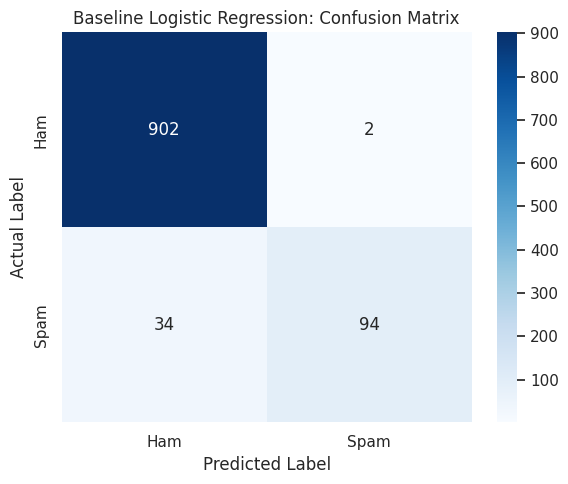

TN: 902
FP: 2
FN: 34
TP: 94


In [13]:

# Generate the confusion matrix

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

# Visualize the confusion matrix

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Baseline Logistic Regression: Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print("TN:", cm[0, 0])
print("FP:", cm[0, 1])
print("FN:", cm[1, 0])
print("TP:", cm[1, 1])



## 13. Model Improvement Experiments

### Experiment 1: Handling Class Imbalance

The dataset contains substantially more ham messages than spam messages. To investigate whether this imbalance affects spam detection, a class-weighted Logistic Regression model will be compared with an unweighted baseline.

A validation set is created from the training data for model comparison. TF-IDF is fitted only on the corresponding training portion to prevent information leakage during validation.

The primary objective is to investigate whether balanced class weights improve spam recall while maintaining acceptable precision.


In [14]:

# Split the existing training data into training and validation sets

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Subtraining samples:", len(X_subtrain))
print("Validation samples:", len(X_val))

print("\nSubtraining class distribution:")
print(y_subtrain.value_counts().sort_index())

print("\nValidation class distribution:")
print(y_val.value_counts().sort_index())


Subtraining samples: 3300
Validation samples: 825

Subtraining class distribution:
Category
0    2890
1     410
Name: count, dtype: int64

Validation class distribution:
Category
0    722
1    103
Name: count, dtype: int64


In [15]:

from sklearn.pipeline import Pipeline

# Define two models with identical TF-IDF settings

validation_models = {
    "Unweighted Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            min_df=1
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight=None
        ))
    ]),

    "Balanced Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            min_df=1
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ])
}

# Train and evaluate both models on the validation set

validation_results = []

for model_name, experiment_model in validation_models.items():

    experiment_model.fit(X_subtrain, y_subtrain)

    val_predictions = experiment_model.predict(X_val)

    validation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, val_predictions),
        "Spam Precision": precision_score(
            y_val, val_predictions, pos_label=1, zero_division=0
        ),
        "Spam Recall": recall_score(
            y_val, val_predictions, pos_label=1, zero_division=0
        ),
        "Spam F1-score": f1_score(
            y_val, val_predictions, pos_label=1, zero_division=0
        )
    })

validation_results_df = pd.DataFrame(validation_results)

display(
    validation_results_df
    .set_index("Model")
    .round(4)
)


,Accuracy,Spam Precision,Spam Recall,Spam F1-score
Model,,,,
Unweighted Logistic Regression,0.9527,1.000,0.6214,0.7665
Balanced Logistic Regression,0.9830,0.932,0.9320,0.9320


## 14. Final Model Training and Test Evaluation

Based on the validation results, the class-weighted Logistic Regression model is selected for further evaluation.

The selected model is retrained on the complete training set and evaluated on the held-out test set. The final evaluation focuses on spam precision, recall, F1-score, and the confusion matrix.

The baseline test results are retained for comparison.

In [16]:
from sklearn.pipeline import Pipeline

final_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        min_df=1
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train on the complete training set
final_model.fit(X_train, y_train)

# Predict on the held-out test set
y_test_pred_balanced = final_model.predict(X_test)

print("Final model training completed.")
print("Test samples:", len(X_test))

Final model training completed.
Test samples: 1032


In [17]:
final_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred_balanced),
    "Spam Precision": precision_score(
        y_test, y_test_pred_balanced, pos_label=1, zero_division=0
    ),
    "Spam Recall": recall_score(
        y_test, y_test_pred_balanced, pos_label=1, zero_division=0
    ),
    "Spam F1-score": f1_score(
        y_test, y_test_pred_balanced, pos_label=1, zero_division=0
    )
}

final_metrics_df = pd.DataFrame(
    final_metrics.items(),
    columns=["Metric", "Score"]
)

display(final_metrics_df.round(4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_balanced,
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

,Metric,Score
0,Accuracy,0.9748
1,Spam Precision,0.8984
2,Spam Recall,0.8984
3,Spam F1-score,0.8984



Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       904
        Spam       0.90      0.90      0.90       128

    accuracy                           0.97      1032
   macro avg       0.94      0.94      0.94      1032
weighted avg       0.97      0.97      0.97      1032



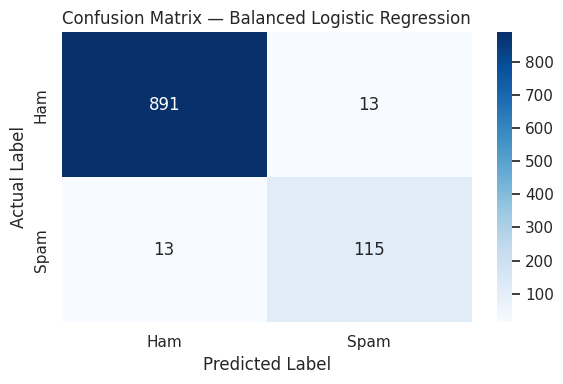

In [18]:
cm_balanced = confusion_matrix(
    y_test,
    y_test_pred_balanced,
    labels=[0, 1]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_balanced,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix — Balanced Logistic Regression")
plt.tight_layout()
plt.show()

## 15. Error Analysis

Error analysis examines messages that the model classified incorrectly. It helps identify patterns in false positives and false negatives and reveals possible limitations of the current approach.

- False positives: legitimate messages incorrectly classified as spam.
- False negatives: spam messages incorrectly classified as legitimate.

The goal is to understand model weaknesses before considering further improvements.

In [20]:
error_analysis = pd.DataFrame({
    "Message": X_test,
    "Actual": y_test,
    "Predicted": y_test_pred_balanced
})

error_analysis["Actual"] = error_analysis["Actual"].map({
    0: "Ham",
    1: "Spam"
})

error_analysis["Predicted"] = error_analysis["Predicted"].map({
    0: "Ham",
    1: "Spam"
})

# Keep only incorrectly classified messages
errors = error_analysis[
    error_analysis["Actual"] != error_analysis["Predicted"]
].copy()

errors["Error Type"] = errors.apply(
    lambda row: (
        "False Positive"
        if row["Actual"] == "Ham"
        else "False Negative"
    ),
    axis=1
)

print("Total misclassified messages:", len(errors))
print("\nError type counts:")
print(errors["Error Type"].value_counts())

print("\nFalse Positives — legitimate messages classified as spam:")
display(
    errors[errors["Error Type"] == "False Positive"][
        ["Message", "Actual", "Predicted"]
    ].head(10)
)

print("\nFalse Negatives — spam messages classified as ham:")
display(
    errors[errors["Error Type"] == "False Negative"][
        ["Message", "Actual", "Predicted"]
    ].head(10)
)

Total misclassified messages: 26

Error type counts:
Error Type
False Positive    13
False Negative    13
Name: count, dtype: int64

False Positives — legitimate messages classified as spam:


,Message,Actual,Predicted
3475,"Sir, i am waiting for your call, once free please call me.",Ham,Spam
4409,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phon...,Ham,Spam
1617,Glad to see your reply.,Ham,Spam
486,Are you free now?can i call now?,Ham,Spam
1978,.Please charge my mobile when you get up in morning.,Ham,Spam
802,On the road so cant txt,Ham,Spam
2195,Dont you have message offer,Ham,Spam
177,Text her. If she doesnt reply let me know so i can have her log in,Ham,Spam
1138,Happy new years melody!,Ham,Spam
4104,what are your new years plans?,Ham,Spam



False Negatives — spam messages classified as ham:


,Message,Actual,Predicted
1229,Can U get 2 phone NOW? I wanna chat 2 set up meet Call me NOW on 09096102316 U can cum here 2mor...,Spam,Ham
3630,"Oh my god! I've found your number again! I'm so glad, text me back xafter this msgs cst std ntwk...",Spam,Ham
3943,Missed call alert. These numbers called but left no message. 07008009200,Spam,Ham
3817,TBS/PERSOLVO. been chasing us since Sept for£38 definitely not paying now thanks to your informa...,Spam,Ham
2541,"Hello darling how are you today? I would love to have a chat, why dont you tell me what you look...",Spam,Ham
4179,Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min,Spam,Ham
496,#ERROR!,Spam,Ham
5125,Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min Gsex POBOX 2667 WC1N 3XX,Spam,Ham
4977,dating:i have had two of these. Only started after i sent a text to talk sport radio last week. ...,Spam,Ham
1420,Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave...,Spam,Ham


## 16. Prediction Confidence Analysis

This section examines the predicted spam probabilities of misclassified messages. The analysis helps determine whether errors occur near the classification threshold or when the model is highly confident in an incorrect prediction.

For binary classification, a default threshold of 0.50 is used to convert predicted probabilities into class labels.

In [21]:
# Obtain spam probabilities from the final pipeline
y_test_spam_probability = final_model.predict_proba(X_test)[:, 1]

# Build a probability analysis table
probability_analysis = pd.DataFrame({
    "Message": X_test,
    "Actual": y_test,
    "Predicted": y_test_pred_balanced,
    "Spam Probability": y_test_spam_probability
})

probability_analysis["Actual"] = probability_analysis["Actual"].map({
    0: "Ham",
    1: "Spam"
})

probability_analysis["Predicted"] = probability_analysis["Predicted"].map({
    0: "Ham",
    1: "Spam"
})

probability_analysis["Correct"] = (
    probability_analysis["Actual"] ==
    probability_analysis["Predicted"]
)

# Show the most confidently incorrect predictions first
incorrect_predictions = probability_analysis[
    ~probability_analysis["Correct"]
].copy()

incorrect_predictions["Confidence in Wrong Prediction"] = np.where(
    incorrect_predictions["Predicted"] == "Spam",
    incorrect_predictions["Spam Probability"],
    1 - incorrect_predictions["Spam Probability"]
)

display(
    incorrect_predictions.sort_values(
        "Confidence in Wrong Prediction",
        ascending=False
    )[
        [
            "Message",
            "Actual",
            "Predicted",
            "Spam Probability",
            "Confidence in Wrong Prediction"
        ]
    ].round(4)
)

,Message,Actual,Predicted,Spam Probability,Confidence in Wrong Prediction
486,Are you free now?can i call now?,Ham,Spam,0.9246,0.9246
4797,K k:) sms chat with me.,Ham,Spam,0.8889,0.8889
3884,In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-...,Spam,Ham,0.1303,0.8697
4409,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phon...,Ham,Spam,0.8026,0.8026
2541,"Hello darling how are you today? I would love to have a chat, why dont you tell me what you look...",Spam,Ham,0.2041,0.7959
802,On the road so cant txt,Ham,Spam,0.7820,0.7820
496,#ERROR!,Spam,Ham,0.2188,0.7812
3817,TBS/PERSOLVO. been chasing us since Sept for£38 definitely not paying now thanks to your informa...,Spam,Ham,0.2219,0.7781
4179,Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min,Spam,Ham,0.2906,0.7094
1420,Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave...,Spam,Ham,0.3016,0.6984


## 17. Decision Threshold Tuning

The default classification threshold is 0.50. This experiment evaluates alternative thresholds using the validation set to investigate the trade-off between spam precision and spam recall.

The threshold is selected using validation performance, while the test set is reserved for evaluating the chosen configuration.

In [22]:
# Use the balanced model trained on the subtraining data
balanced_validation_model = validation_models[
    "Balanced Logistic Regression"
]

# Obtain spam probabilities for validation samples
y_val_spam_probability = balanced_validation_model.predict_proba(X_val)[:, 1]

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]
threshold_results = []

for threshold in thresholds:
    y_val_pred_threshold = (
        y_val_spam_probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_val_pred_threshold,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, y_val_pred_threshold),
        "Spam Precision": precision_score(
            y_val, y_val_pred_threshold,
            pos_label=1, zero_division=0
        ),
        "Spam Recall": recall_score(
            y_val, y_val_pred_threshold,
            pos_label=1, zero_division=0
        ),
        "Spam F1-score": f1_score(
            y_val, y_val_pred_threshold,
            pos_label=1, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn
    })

threshold_results_df = pd.DataFrame(threshold_results)

display(
    threshold_results_df
    .set_index("Threshold")
    .round(4)
)

,Accuracy,Spam Precision,Spam Recall,Spam F1-score,False Positives,False Negatives
Threshold,,,,,,
0.3,0.9479,0.7113,0.9806,0.8245,41,2
0.4,0.9721,0.8448,0.9515,0.8950,18,5
0.5,0.9830,0.9320,0.9320,0.9320,7,7
0.6,0.9842,0.9787,0.8932,0.9340,2,11
0.7,0.9806,1.0000,0.8447,0.9158,0,16


## 18. Final Threshold Evaluation

A decision threshold of 0.50 is selected based on the validation results and the project's goal of balancing spam precision and recall.

The selected threshold is evaluated on the held-out test set to report the final performance of the threshold-based classifier.

Selected threshold: 0.5

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       904
        Spam       0.90      0.90      0.90       128

    accuracy                           0.97      1032
   macro avg       0.94      0.94      0.94      1032
weighted avg       0.97      0.97      0.97      1032



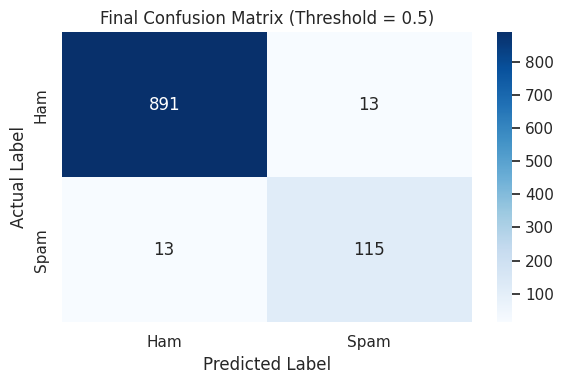

In [23]:
selected_threshold = 0.50

# Obtain probabilities from the final model
y_test_spam_probability = final_model.predict_proba(X_test)[:, 1]

# Convert probabilities to class predictions
y_test_pred_final = (
    y_test_spam_probability >= selected_threshold
).astype(int)

# Final metrics
print("Selected threshold:", selected_threshold)
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_final,
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

# Confusion matrix
cm_final = confusion_matrix(
    y_test,
    y_test_pred_final,
    labels=[0, 1]
)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title(f"Final Confusion Matrix (Threshold = {selected_threshold})")
plt.tight_layout()
plt.show()